In [ ]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

### Define State

In [5]:
class NameState(TypedDict):
    name: str
    uppercase_name: str
    greeting: str

### First Node (Convert name to uppercase)

In [6]:
def convert_name(state: NameState) -> NameState:
    name = state["name"]

    state["uppercase_name"] = name.upper()

    return state


### Second node: create a greeting

In [7]:
def create_greeting(state: NameState) -> NameState:
    name = state["uppercase_name"]

    state["greeting"] = "Hello, " + name + "!"

    return state

### Define and Compile Graph

In [8]:
graph = StateGraph(NameState)


# Add nodes
graph.add_node("convert_name", convert_name)
graph.add_node("create_greeting", create_greeting)


# Add edges
graph.add_edge(START, "convert_name")
graph.add_edge("convert_name", "create_greeting")
graph.add_edge("create_greeting", END)


# Compile the graph
workflow = graph.compile()


### Execute Graph

In [9]:
# Execute the graph
initial_state = {
    "name": "Amna"
}

final_state = workflow.invoke(initial_state)

print(final_state)

{'name': 'Amna', 'uppercase_name': 'AMNA', 'greeting': 'Hello, AMNA!'}


### Visualize graph

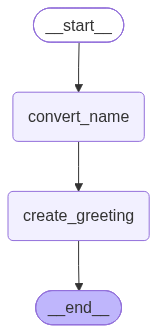

In [16]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())